# 02. 데이터 전처리·분석·문제해결 (배터리 전압·용량 데이터 불량 개선)
**DMAIC** 흐름으로 진행합니다.

| 단계 | 내용 |
|---|---|
| **D**efine | 문제 정의: 측정 데이터에 섞인 불량이 OCV 피팅·ICA 분석을 왜곡한다 |
| **M**easure | 데이터 점검, 불량 현황 파악, 단순 통계 기법의 한계 확인 |
| **A**nalyze | 불량 유형별 탐지 알고리즘 설계 및 성능 평가, 파레토·관리도 분석 |
| **I**mprove | 자동 보정 알고리즘 적용, 개선 효과 검증 (보정 오차, OCV 피팅, ICA) |
| **C**ontrol | 관리 기준(임계값) 정리, 다른 불량 시나리오로 재현성 검증, 결과 저장 |

### 실제 사례와 이 노트북의 관계
- **실제 불량**: 초기 양극 샘플1(교반 1회)이 이론 용량의 약 50%에 그침 → 원인은 슬러리 점도(바인더 과다 유입)와 교반 부족, 교반 2회로 개선 후 정상 셀 확인. 자세한 원인 분석은 `03_원인분석_4M_5Why.ipynb`의 0절에 있습니다.
- 이 노트북의 불량 6종은 위 용량 저하 셀의 충방전 데이터가 아니라, 탐지·보정 알고리즘을 만들고 검증하려고 **정상 셀 데이터에 불량을 주입해 만든 불량 시나리오 데이터**입니다.
- 개선 후 정상 셀(샘플2) 데이터가 이 노트북의 **정상 기준 데이터**(`전압 및 용량 데이터.xlsx`)입니다.

> `data/불량 시나리오 데이터.xlsx`는 `01_불량시나리오_생성.ipynb`가 만든 파일이며, 저장소에 이미 포함되어 있습니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import LSQUnivariateSpline
from scipy.ndimage import label as cc_label
from scipy.optimize import curve_fit

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

from pathlib import Path

# 저장소 루트에서 실행하든 notebooks/ 폴더에서 실행하든 동작
DATA_DIR = next(p for p in (Path("data"), Path("../data")) if p.exists())
OUT_DIR = DATA_DIR.parent / "outputs"          # 생성되는 결과 파일 (git에는 올리지 않음)
IMG_DIR = DATA_DIR.parent / "images"
OUT_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)
pd.set_option('display.width', 200)

BAD_FILE = DATA_DIR / "불량 시나리오 데이터.xlsx"      # 불량이 섞인 측정 데이터 (분석 대상)
REF_FILE = DATA_DIR / "전압 및 용량 데이터.xlsx"        # 정상 기준 데이터 (정답 확인용, 알고리즘 입력에는 쓰지 않음)

bad = pd.read_excel(BAD_FILE)
ref = pd.read_excel(REF_FILE)
VC, QC = '전압(V)', '누적 용량_d(Ah/cm2)'
TYPES = ['데이터 누락', '센서 고착', '센서 스파이크', '용량 글리치', '과전압', '내부 단락 의심']
print(f"분석 대상: {len(bad):,}행  /  정답 라벨 불량: {bad['불량'].sum():,}행 ({bad['불량'].mean()*100:.1f}%)")

분석 대상: 34,864행  /  정답 라벨 불량: 1,400행 (4.0%)


## 1. Define / Measure — 데이터 점검과 불량 현황

In [2]:
print("[결측치]"); print(bad[[VC, QC]].isna().sum().to_string())
print("\n[기초 통계]"); print(bad[[VC, QC]].describe().round(6).to_string())
print("\n[불량 유형별 현황 (정답 라벨)]")
cnt = bad['불량유형'].value_counts()
print(pd.DataFrame({'행 수': cnt, '비율(%)': (cnt / len(bad) * 100).round(2)}).to_string())

[결측치]
전압(V)              40
누적 용량_d(Ah/cm2)     0

[기초 통계]
              전압(V)  누적 용량_d(Ah/cm2)
count  34824.000000     34864.000000
mean       3.692845         0.000845
std        0.252184         0.000346
min        2.799860         0.000246
25%        3.543410         0.000546
50%        3.666100         0.000845
75%        3.875570         0.001144
max        4.350020         0.001444

[불량 유형별 현황 (정답 라벨)]
            행 수  비율(%)
불량유형                  
정상        33464  95.98
내부 단락 의심   1000   2.87
센서 고착       200   0.57
과전압         151   0.43
데이터 누락       40   0.11
센서 스파이크       6   0.02
용량 글리치        3   0.01


### 단순 통계 기법(Z-score, IQR)으로 불량을 찾으면?
흔히 쓰는 이상치 기준을 그대로 적용해 보고, 정답 라벨과 비교합니다.

In [3]:
def binary_metrics(flag, truth):
    tp = int((flag & truth).sum()); fp = int((flag & ~truth).sum()); fn = int((~flag & truth).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(탐지수=tp + fp, TP=tp, FP=fp, FN=fn, 정밀도=round(prec, 3), 재현율=round(rec, 3), F1=round(f1, 3))

truth = bad['불량'].to_numpy().astype(bool)
v = bad[VC]
z = ((v - v.mean()) / v.std()).abs() > 3
q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
iqr_flag = (v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)
naive = pd.DataFrame({'Z-score(|z|>3)': binary_metrics(z.to_numpy(), truth),
                      'IQR(1.5배)': binary_metrics(iqr_flag.to_numpy(), truth)}).T
print(naive.to_string())
print("\n→ 정밀도가 매우 낮다: 충·방전 시작/끝의 정상적인 전압 변화를 불량으로 오인하고,")
print("  정상 전압 범위 안에서 튄 값(스파이크 등)은 놓친다. 데이터 특성을 반영한 탐지 규칙이 필요하다.")

                  탐지수   TP     FP      FN  정밀도  재현율   F1
Z-score(|z|>3)  334.0  0.0  334.0  1400.0  0.0  0.0  0.0
IQR(1.5배)       692.0  0.0  692.0  1400.0  0.0  0.0  0.0

→ 정밀도가 매우 낮다: 충·방전 시작/끝의 정상적인 전압 변화를 불량으로 오인하고,
  정상 전압 범위 안에서 튄 값(스파이크 등)은 놓친다. 데이터 특성을 반영한 탐지 규칙이 필요하다.


## 2. Analyze — 불량 유형별 탐지 알고리즘

| 불량 유형 | 탐지 방법 | 근거 |
|---|---|---|
| 데이터 누락 | 전압/용량이 NaN | 결측 |
| 센서 고착 | 같은 전압값이 `flat_run`개 이상 연속 | 정상 데이터에서 같은 값은 최대 10개 연속 |
| 센서 스파이크 | 이동 중앙값(11점)과의 차이가 `spike_v` 초과 (Hampel 필터) | 정상 1초 변화량은 최대 0.045 V |
| 용량 글리치 | 이동 중앙값과의 차이가 용량 증가량 중앙값의 `glitch_k`배 초과 | 정상에서는 한 점씩 일정하게 변함 |
| 과전압 | 전압이 상한 `v_max` 초과 | 충전 상한 4.2 V |
| 내부 단락 의심 | **로버스트 스플라인 기준선** 대비 전압이 지속적으로 낮음 | 이상치를 반복 제외하며 곡선을 맞춘 뒤 잔차로 판정 |

In [4]:
PARAM = dict(
    flat_run=30,          # 고착: 동일 전압값 연속 개수
    spike_v=0.10,         # 스파이크: 이동중앙값 대비 편차 (V)
    glitch_k=50,          # 용량 글리치: 정상 증가량 중앙값의 배수
    v_max=4.201,          # 과전압: 충전 상한 4.2V + 허용오차
    short_knots=20,       # 내부 단락: 스플라인 매듭 수
    short_core=0.02,      # 내부 단락: 핵심 판정 편차 (V)
    short_grow=0.006,     # 내부 단락: 구간 확장 기준 편차 (V)
    short_minrun=100,     # 내부 단락: 최소 지속 길이 (샘플)
    short_edge=300,       # 내부 단락: 구간 양 끝 판정 제외 (충·방전 시작/끝은 정상적으로 급변)
)


def split_phase(Q):
    """충전→방전 전환 행 번호 (용량이 최대인 지점)."""
    Qs = pd.Series(Q).interpolate(limit_direction='both').rolling(11, center=True, min_periods=1).median()
    return int(np.argmax(Qs.to_numpy()))


def run_length(x):
    s = pd.Series(x)
    return s.groupby((s != s.shift()).cumsum()).transform('size').to_numpy()


def hampel_residual(x, w=11):
    s = pd.Series(x)
    return (s - s.rolling(w, center=True, min_periods=3).median()).to_numpy()


def robust_baseline(v, valid, nknots, c=0.02, iters=8):
    """이상치에 둔감한 스플라인 기준선 (Tukey bisquare 가중 반복 적합)."""
    x = np.arange(len(v), dtype=float)
    w = valid.astype(float)
    knots = np.linspace(x[0], x[-1], nknots + 2)[1:-1]
    for _ in range(iters):
        m = w > 0
        sp = LSQUnivariateSpline(x[m], v[m], knots, k=3)
        res = v - sp(x)
        s = max(1.4826 * np.median(np.abs(res[m] - np.median(res[m]))), 0.002)
        u = res / (c + 4.685 * s)
        w = np.where(np.abs(u) < 1, (1 - u ** 2) ** 2, 0.0) * valid
    return sp(x), res, s


def grow_runs(res, valid, P):
    """잔차가 지속적으로 낮은 구간을 찾아 양쪽으로 확장."""
    f = (res < -P['short_core']) & valid
    f[:P['short_edge']] = False
    f[-P['short_edge']:] = False
    idx = np.flatnonzero(f)
    for a, b in zip(idx[:-1], idx[1:]):          # 50샘플 이내 간격은 한 덩어리로
        if b - a <= 50:
            f[a:b + 1] = True
    lbl, n = cc_label(f)
    out = np.zeros_like(f)
    for k in range(1, n + 1):
        pts = np.flatnonzero(lbl == k)
        if len(pts) < P['short_minrun']:
            continue
        a, b = pts[0], pts[-1]
        while a > 0 and res[a - 1] < -P['short_grow']:
            a -= 1
        while b < len(res) - 1 and res[b + 1] < -P['short_grow']:
            b += 1
        out[a:b + 1] = True
    return out


def detect_defects(df, P=PARAM):
    """행마다 불량 유형을 판정. (우선순위: 위에서부터, 먼저 판정된 유형 유지)"""
    V = df[VC].to_numpy(float)
    Q = df[QC].to_numpy(float)
    n = len(V)
    typ = np.full(n, '정상', dtype=object)

    def mark(mask, name):
        typ[mask & (typ == '정상')] = name

    mark(np.isnan(V) | np.isnan(Q), '데이터 누락')
    mark(run_length(V) >= P['flat_run'], '센서 고착')

    Vc = np.where(typ == '정상', V, np.nan)
    mark(np.abs(hampel_residual(Vc)) > P['spike_v'], '센서 스파이크')

    res_q = hampel_residual(Q)
    step = np.nanmedian(np.abs(np.diff(Q)))
    mark(np.abs(res_q) > P['glitch_k'] * step, '용량 글리치')

    mark(V > P['v_max'], '과전압')

    # 내부 단락: 충전/방전 구간을 따로 기준선 적합
    imax = split_phase(Q)
    Vf = pd.Series(V).interpolate(limit_direction='both').to_numpy()
    res_all = np.zeros(n)
    for sl in (slice(0, imax + 1), slice(imax + 1, n)):
        valid = typ[sl] == '정상'
        base, res, _ = robust_baseline(Vf[sl], valid, P['short_knots'])
        res_all[sl] = res
        mark_mask = np.zeros(n, bool)
        mark_mask[sl] = grow_runs(res, valid, P)
        mark(mark_mask, '내부 단락 의심')
    return typ, dict(imax=imax, residual=res_all)


typ, diag = detect_defects(bad)
imax = diag['imax']
print(f"충전→방전 전환 행: {imax}")
print(pd.Series(typ).value_counts().to_string())

충전→방전 전환 행: 17424
정상          33734
내부 단락 의심      741
센서 고착         200
과전압           140
데이터 누락         40
센서 스파이크         6
용량 글리치          3


In [5]:
# 탐지 성능: 유형별 정밀도 / 재현율
true_typ = bad['불량유형'].to_numpy()
rows = []
for t in TYPES:
    d, g = typ == t, true_typ == t
    tp = int((d & g).sum())
    rows.append(dict(불량유형=t, 실제=int(g.sum()), 탐지=int(d.sum()), 정확히_맞춤=tp,
                     정밀도=round(tp / d.sum(), 3) if d.sum() else np.nan,
                     재현율=round(tp / g.sum(), 3) if g.sum() else np.nan))
perf = pd.DataFrame(rows).set_index('불량유형')
print(perf.to_string())
overall = binary_metrics(typ != '정상', truth)
print("\n[전체: 불량/정상 이진 판정]", overall)
print("[단순 통계 대비]  Z-score F1 =", naive.loc['Z-score(|z|>3)', 'F1'], " IQR F1 =", naive.loc['IQR(1.5배)', 'F1'], " 제안 알고리즘 F1 =", overall['F1'])

            실제   탐지  정확히_맞춤  정밀도    재현율
불량유형                                   
데이터 누락      40   40      40  1.0  1.000
센서 고착      200  200     200  1.0  1.000
센서 스파이크      6    6       6  1.0  1.000
용량 글리치       3    3       3  1.0  1.000
과전압        151  140     140  1.0  0.927
내부 단락 의심  1000  741     741  1.0  0.741

[전체: 불량/정상 이진 판정] {'탐지수': 1130, 'TP': 1130, 'FP': 0, 'FN': 270, '정밀도': 1.0, '재현율': 0.807, 'F1': 0.893}
[단순 통계 대비]  Z-score F1 = 0.0  IQR F1 = 0.0  제안 알고리즘 F1 = 0.893


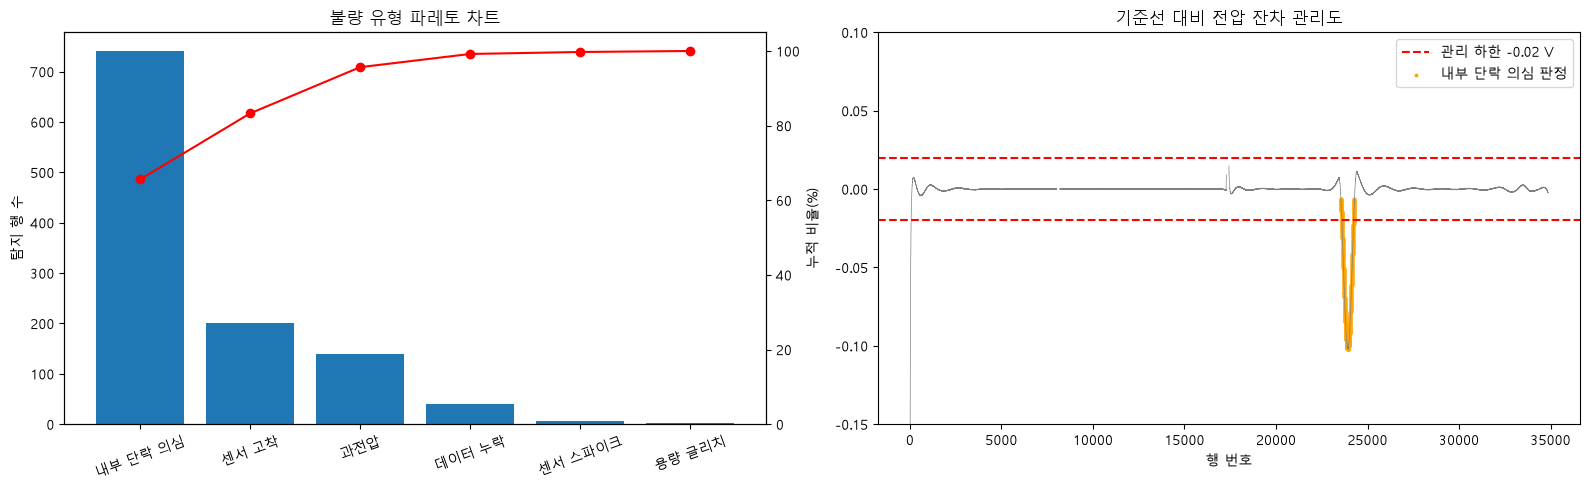

In [6]:
# 파레토 차트(탐지된 불량 유형별 건수)와 내부 단락 판정용 잔차 관리도
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pc = pd.Series(typ[typ != '정상']).value_counts()
cum = pc.cumsum() / pc.sum() * 100
axes[0].bar(pc.index, pc.values, color='tab:blue')
axes[0].set_ylabel('탐지 행 수'); axes[0].set_title('불량 유형 파레토 차트')
ax2 = axes[0].twinx(); ax2.plot(pc.index, cum.values, 'r-o'); ax2.set_ylim(0, 105); ax2.set_ylabel('누적 비율(%)')
axes[0].tick_params(axis='x', rotation=20)

res = np.where(np.isin(typ, ['정상', '내부 단락 의심']), diag['residual'], np.nan)   # 판정에 쓰인 점만 표시
x = np.arange(len(res))
axes[1].plot(x, res, lw=0.5, color='gray')
axes[1].axhline(-PARAM['short_core'], color='r', ls='--', label=f"관리 하한 -{PARAM['short_core']} V")
axes[1].axhline(PARAM['short_core'], color='r', ls='--')
sh = typ == '내부 단락 의심'
axes[1].scatter(x[sh], res[sh], s=3, color='orange', label='내부 단락 의심 판정')
axes[1].set_ylim(-0.15, 0.1); axes[1].set_title('기준선 대비 전압 잔차 관리도'); axes[1].set_xlabel('행 번호')
axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Improve — 자동 보정 알고리즘

불량의 성격에 따라 조치를 나눕니다.

| 구분 | 불량 | 조치 |
|---|---|---|
| 측정 오류 | 누락, 고착, 스파이크, 용량 글리치 | **선형 보간으로 복원** |
| 셀/공정 이상 | 과전압, 내부 단락 의심 | 실제 이상 현상이므로 **복원하지 않고 경보 + 분석 제외** |

In [7]:
def repair(df, typ):
    out = df.copy()
    V = out[VC].to_numpy(float).copy()
    Q = out[QC].to_numpy(float).copy()
    V[np.isin(typ, ['데이터 누락', '센서 고착', '센서 스파이크'])] = np.nan
    Q[np.isin(typ, ['데이터 누락', '용량 글리치'])] = np.nan
    out['전압_보정'] = pd.Series(V).interpolate(limit_direction='both').to_numpy()
    out['용량_보정'] = pd.Series(Q).interpolate(limit_direction='both').to_numpy()
    out['탐지유형'] = typ
    out['조치'] = np.select([np.isin(typ, ['데이터 누락', '센서 고착', '센서 스파이크', '용량 글리치']),
                            np.isin(typ, ['과전압', '내부 단락 의심'])],
                           ['보간 복원', '경보/분석 제외'], '정상')
    out['분석제외'] = np.isin(typ, ['과전압', '내부 단락 의심'])
    return out


clean = repair(bad, typ)
print(clean['조치'].value_counts().to_string())

# 복원 정확도: 정상 기준 데이터와 비교
fix_v = np.isin(typ, ['데이터 누락', '센서 고착', '센서 스파이크'])
fix_q = np.isin(typ, ['용량 글리치'])
Vb, Va, Vr = bad[VC].to_numpy(float), clean['전압_보정'].to_numpy(), ref[VC].to_numpy(float)
Qb, Qa, Qr = bad[QC].to_numpy(float), clean['용량_보정'].to_numpy(), ref[QC].to_numpy(float)
ok = fix_v & ~np.isnan(Vb)
print("\n[복원 오차: 측정 오류로 판정된 행]")
print(f" 전압 RMSE  보정 전 {np.sqrt(np.mean((Vb[ok]-Vr[ok])**2))*1000:8.1f} mV  →  보정 후 {np.sqrt(np.mean((Va[fix_v]-Vr[fix_v])**2))*1000:6.2f} mV")
print(f" 전압 최대오차 보정 전 {np.abs(Vb[ok]-Vr[ok]).max()*1000:8.1f} mV  →  보정 후 {np.abs(Va[fix_v]-Vr[fix_v]).max()*1000:6.2f} mV")
print(f" 용량 RMSE  보정 전 {np.sqrt(np.mean((Qb[fix_q]-Qr[fix_q])**2)):.2e}  →  보정 후 {np.sqrt(np.mean((Qa[fix_q]-Qr[fix_q])**2)):.2e}")

조치
정상          33734
경보/분석 제외      881
보간 복원         249

[복원 오차: 측정 오류로 판정된 행]
 전압 RMSE  보정 전     40.6 mV  →  보정 후   0.14 mV
 전압 최대오차 보정 전    289.0 mV  →  보정 후   0.42 mV
 용량 RMSE  보정 전 8.00e-05  →  보정 후 4.08e-12


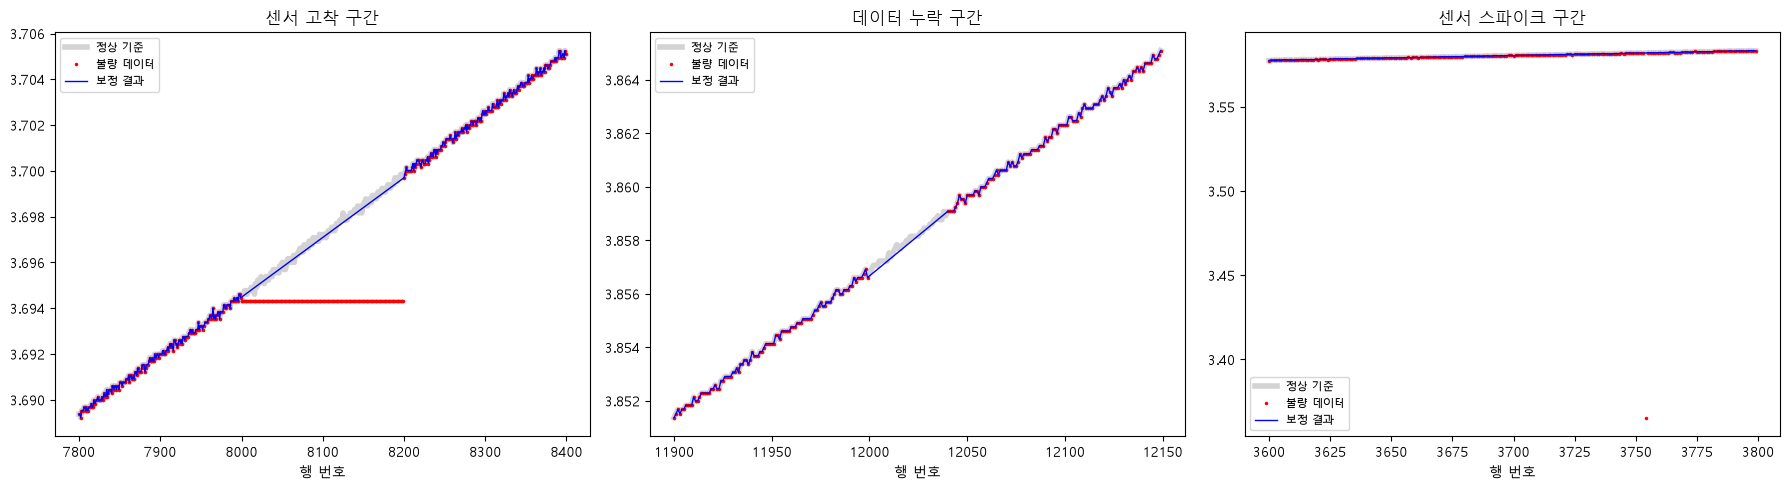

In [8]:
# 보정 전/후 시각화 (측정 오류가 있던 구간 확대)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (lo, hi, title) in zip(axes, [(7800, 8400, '센서 고착 구간'), (11900, 12150, '데이터 누락 구간'), (3600, 3800, '센서 스파이크 구간')]):
    r = slice(lo, hi)
    ax.plot(np.arange(len(Vr))[r], Vr[r], color='lightgray', lw=4, label='정상 기준')
    ax.plot(np.arange(len(Vb))[r], Vb[r], 'r.', ms=3, label='불량 데이터')
    ax.plot(np.arange(len(Va))[r], Va[r], 'b-', lw=1, label='보정 결과')
    ax.set_title(title); ax.set_xlabel('행 번호'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 개선 효과 검증: OCV 피팅과 ICA(dQ/dV)
분석 결과가 정상 기준 데이터와 얼마나 가까운지 비교합니다. 충전 구간만 사용합니다(충·방전이 섞이면 히스테리시스 때문에 왜곡됨).
- **정상 기준**: 불량 없는 원본
- **불량 그대로**: 불량 데이터에서 NaN만 제거
- **정제 후**: 보정 + 분석 제외 적용

        OCV피팅_RMSE_mV  ICA_RMSE  ICA_최대오차
데이터                                      
불량 그대로           2.84  0.003704  0.031081
정제 후             0.34  0.000098  0.000872


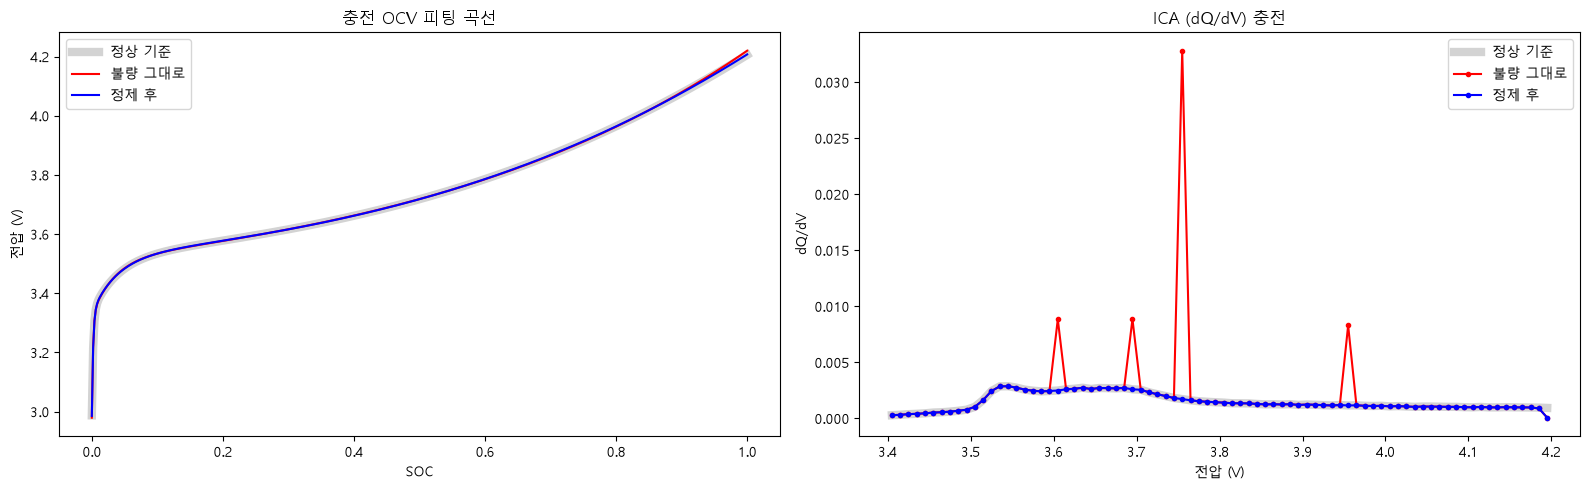

In [9]:
def sigmoid_model(soc, a0, a1, k1, c1, a2, k2, c2, a3, k3, c3):
    e = lambda k, c: 1 / (1 + np.exp(np.clip(-k * (soc - c), -50, 50)))
    return a0 + a1 * e(k1, c1) + a2 * e(k2, c2) + a3 * e(k3, c3)


def ocv_fit(Vc_, Qc_, keep):
    """SOC는 (제외 전) 충전 구간 전체 용량으로 정규화하고, 사용 가능한 행(keep)만 피팅."""
    soc = (Qc_ - np.nanmin(Qc_)) / (np.nanmax(Qc_) - np.nanmin(Qc_))
    p0 = [np.mean(Vc_[keep]), 0.1, 10, 0.2, 0.1, 10, 0.5, 0.1, 10, 0.8]
    popt, _ = curve_fit(sigmoid_model, soc[keep], Vc_[keep], p0=p0, maxfev=20000)
    return popt


def ica_curve(Vc_, Qc_, edges):
    """전압 구간(bin)별 용량 변화량 / 전압폭 = dQ/dV"""
    out = np.full(len(edges) - 1, np.nan)
    for i in range(len(edges) - 1):
        m = (Vc_ >= edges[i]) & (Vc_ < edges[i + 1])
        if m.sum() >= 2:
            out[i] = (Qc_[m].max() - Qc_[m].min()) / (edges[i + 1] - edges[i])
    return out


ch = slice(0, imax + 1)
# (전압, 용량, 사용할 행) -- 정제 후는 분석 제외 행을 뺌, 불량 그대로는 NaN만 뺌
sets = {
    '정상 기준': (Vr[ch], Qr[ch], np.ones(imax + 1, bool)),
    '불량 그대로': (Vb[ch], Qb[ch], ~np.isnan(Vb[ch])),
    '정제 후': (Va[ch], Qa[ch], ~clean['분석제외'].to_numpy()[ch]),
}
edges = np.arange(3.40, 4.20, 0.01)
mid = (edges[:-1] + edges[1:]) / 2
soc_grid = np.linspace(0, 1, 500)
fits, icas = {}, {}
for name, (v_, q_, keep) in sets.items():
    popt = ocv_fit(v_, q_, keep)
    fits[name] = sigmoid_model(soc_grid, *popt)
    icas[name] = ica_curve(v_[keep], q_[keep], edges)

rows = []
for name in ('불량 그대로', '정제 후'):
    ocv_err = np.sqrt(np.mean((fits[name] - fits['정상 기준']) ** 2)) * 1000
    m = ~np.isnan(icas[name]) & ~np.isnan(icas['정상 기준'])
    ica_err = np.sqrt(np.mean((icas[name][m] - icas['정상 기준'][m]) ** 2))
    rows.append(dict(데이터=name, OCV피팅_RMSE_mV=round(ocv_err, 2), ICA_RMSE=round(ica_err, 6),
                     ICA_최대오차=round(np.max(np.abs(icas[name][m] - icas['정상 기준'][m])), 6)))
effect = pd.DataFrame(rows).set_index('데이터')
print(effect.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, c, lw in (('정상 기준', 'lightgray', 6), ('불량 그대로', 'red', 1.5), ('정제 후', 'blue', 1.5)):
    axes[0].plot(soc_grid, fits[name], color=c, lw=lw, label=name)
    axes[1].plot(mid, icas[name], color=c, lw=lw, marker='o', ms=3, label=name)
axes[0].set_title('충전 OCV 피팅 곡선'); axes[0].set_xlabel('SOC'); axes[0].set_ylabel('전압 (V)'); axes[0].legend()
axes[1].set_title('ICA (dQ/dV) 충전'); axes[1].set_xlabel('전압 (V)'); axes[1].set_ylabel('dQ/dV'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Control — 관리 기준, 재현성 검증, 결과 저장
위 임계값이 이번 시나리오에만 맞춘 것이 아닌지 확인하기 위해, **불량 위치·크기를 무작위로 바꾼 새 시나리오 10개**를 만들어 같은 알고리즘을 적용합니다.

In [10]:
def inject_defects(df0, seed):
    """불량 위치/크기를 무작위로 주입한 시나리오 생성 (정답 라벨 포함)."""
    rng = np.random.default_rng(seed)
    V = df0[VC].to_numpy(float).copy(); Q = df0[QC].to_numpy(float).copy()
    n = len(V); im = split_phase(Q)
    lab = np.full(n, '정상', dtype=object)
    used = np.zeros(n, bool)

    def place(lo, hi, L):
        for _ in range(200):
            s = int(rng.integers(lo, hi - L))
            if not used[max(0, s - 400):s + L + 400].any():
                used[s:s + L] = True
                return s
        raise RuntimeError('배치 실패')

    L = int(rng.integers(600, 1200)); s = place(im + 2000, n - 2000, L)           # 내부 단락
    V[s:s + L] -= rng.uniform(0.08, 0.15) * np.sin(np.linspace(0, np.pi, L)) ** 2; lab[s:s + L] = '내부 단락 의심'
    L = int(rng.integers(100, 300)); s = place(2000, im - 2000, L)                # 센서 고착
    V[s:s + L] = V[s]; lab[s:s + L] = '센서 고착'
    L = int(rng.integers(20, 60)); s = place(2000, im - 2000, L)                  # 데이터 누락
    V[s:s + L] = np.nan; lab[s:s + L] = '데이터 누락'
    L = int(rng.integers(100, 200)); s = im - L + 1                                # 과전압 (충전 끝)
    V[s:s + L] += np.linspace(0, rng.uniform(0.10, 0.20), L); lab[s:s + L] = '과전압'; used[s - 400:im + 400] = True
    for _ in range(6):                                                              # 스파이크
        i = place(1000, n - 1000, 1)
        V[i] += rng.choice([-1, 1]) * rng.uniform(0.15, 0.30); lab[i] = '센서 스파이크'
    for _ in range(3):                                                              # 용량 글리치
        i = place(1000, im - 1000, 1)
        Q[i] += rng.uniform(0.00005, 0.0001); lab[i] = '용량 글리치'
    out = df0.copy(); out[VC] = V; out[QC] = Q; out['불량유형'] = lab
    return out


results = []
for seed in range(10):
    sc = inject_defects(ref, seed)
    t, _ = detect_defects(sc)
    for name in TYPES:
        d, g = t == name, sc['불량유형'].to_numpy() == name
        tp = int((d & g).sum())
        results.append(dict(seed=seed, 유형=name, 정밀도=tp / d.sum() if d.sum() else np.nan, 재현율=tp / g.sum()))
    ov = binary_metrics(t != '정상', sc['불량유형'].to_numpy() != '정상')
    results.append(dict(seed=seed, 유형='전체', 정밀도=ov['정밀도'], 재현율=ov['재현율']))
rob = pd.DataFrame(results).groupby('유형')[['정밀도', '재현율']].agg(['mean', 'min']).round(3)
print(rob.reindex(TYPES + ['전체']).to_string())

            정밀도           재현율       
           mean    min   mean    min
유형                                  
데이터 누락    1.000  1.000  1.000  1.000
센서 고착     0.991  0.957  1.000  1.000
센서 스파이크   1.000  1.000  1.000  1.000
용량 글리치    1.000  1.000  1.000  1.000
과전압       1.000  1.000  0.926  0.898
내부 단락 의심  1.000  1.000  0.732  0.618
전체        0.999  0.995  0.798  0.707


### 개선 후 정상 셀에 알고리즘 적용 (오탐 점검)
교반 2회로 개선한 샘플2(정상 셀)의 원본 데이터에 같은 알고리즘을 적용해, 정상 데이터를 불량으로 잘못 판정하지 않는지 확인합니다.

In [11]:
typ_ok, _ = detect_defects(ref)
n_flag = int((typ_ok != '정상').sum())
print(f"정상 셀 {len(ref):,}행 중 불량으로 판정된 행: {n_flag}개 ({n_flag / len(ref) * 100:.2f}%)")
print("→ 오탐 없음: 정상 데이터는 모두 '정상'으로 판정" if n_flag == 0 else "→ 오탐 있음: 임계값 점검 필요")

정상 셀 34,864행 중 불량으로 판정된 행: 0개 (0.00%)
→ 오탐 없음: 정상 데이터는 모두 '정상'으로 판정


In [12]:
control = pd.DataFrame([
    ['데이터 누락', '전압/용량 NaN', '결측', '선형 보간'],
    ['센서 고착', f"동일 전압값 {PARAM['flat_run']}개 이상 연속", '센서/통신 점검', '선형 보간'],
    ['센서 스파이크', f"이동중앙값(11) 대비 ±{PARAM['spike_v']} V 초과", '센서/배선 점검', '선형 보간'],
    ['용량 글리치', f"이동중앙값 대비 증가량 중앙값의 {PARAM['glitch_k']}배 초과", '전류 적산기 점검', '선형 보간'],
    ['과전압', f"전압 > {PARAM['v_max']} V", '충전기 상한 설정/보호회로 점검', '경보 + 분석 제외'],
    ['내부 단락 의심', f"기준선 대비 {PARAM['short_core']} V 이상 낮은 상태 {PARAM['short_minrun']}샘플 이상 지속", '셀 격리 및 정밀 검사', '경보 + 분석 제외'],
], columns=['불량 유형', '관리 기준', '원인 점검', '자동 조치']).set_index('불량 유형')
print(control.to_string())

# 결과 저장
clean.to_excel(OUT_DIR / "정제된 데이터.xlsx", index=False)
perf.to_excel(OUT_DIR / "불량 탐지 성능.xlsx")
print("\n저장 완료: outputs/정제된 데이터.xlsx, outputs/불량 탐지 성능.xlsx")

                                       관리 기준              원인 점검       자동 조치
불량 유형                                                                      
데이터 누락                             전압/용량 NaN                 결측       선형 보간
센서 고착                       동일 전압값 30개 이상 연속           센서/통신 점검       선형 보간
센서 스파이크               이동중앙값(11) 대비 ±0.1 V 초과           센서/배선 점검       선형 보간
용량 글리치              이동중앙값 대비 증가량 중앙값의 50배 초과          전류 적산기 점검       선형 보간
과전압                             전압 > 4.201 V  충전기 상한 설정/보호회로 점검  경보 + 분석 제외
내부 단락 의심  기준선 대비 0.02 V 이상 낮은 상태 100샘플 이상 지속       셀 격리 및 정밀 검사  경보 + 분석 제외



저장 완료: outputs/정제된 데이터.xlsx, outputs/불량 탐지 성능.xlsx
